# Rendeiro et al. 2020 — CLL (10x) · Step 01: Preprocessing & Gate 1
**CCCA meta-atlas cell-state analysis.** Chronic lymphocytic leukemia PBMCs, longitudinal ibrutinib time-course.
This notebook loads malignant cells, derives every tunable choice from the data, and evaluates **Gate 1
(mixing + continuity)** on the regenerated embedding across a Harmony integration-strength (θ) sweep with a
per-neighborhood metric (iLISI) — not a single scalar. Runs in place.

In [1]:
import os, sys
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'   # scFates PPT -> rpy2 -> r-mgcv
import numpy as np, pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
np.random.seed(0)

In [2]:
# --- relative paths: notebooks live two levels below Puram (Claude/<Category>/<Dataset>-N/) ---
name = os.path.split(os.getcwd())[1]              # e.g. 'Rendeiro2020_Hematologic-3'
base = name.rsplit('-', 1)[0]                      # strip attempt suffix -> 'Rendeiro2020_Hematologic'
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]   # 'Hematologic'
pth  = os.path.join(*(['..']*4))                 # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
sys.path.append(os.path.join(pth, 'mesencontext', 'scripts'))
from load import load_CCCA_adata
print('dataset:', base, '| category:', cat)

dataset: Rendeiro2020_Hematologic | category: Hematologic


In [3]:
# load dataset -> select malignant cells (loader auto-normalizes counts + log1p, celltype='Malignant')
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print(adata)
print('patients:', adata.obs.patient.value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Rendeiro2020_Hematologic
Done.
AnnData object with n_obs × n_vars = 18854 × 18402
    obs: 'sample', 'patient', 'timepoint', 'cell_type', 'complexity', 'celltype'
    uns: 'log1p'
patients: {'CLL5': 7972, 'CLL6': 6973, 'CLL1': 2273, 'CLL8': 1636}


### Sample threshold — derived by gap-finding (C1/C2)
Sort per-sample malignant counts and cut at the largest multiplicative gap between consecutive counts,
rather than inheriting the anchor's ≥100 constant.

In [4]:
n = adata.obs['sample'].value_counts().sort_values(ascending=False)
counts = n.values.astype(float)
ratios = counts[:-1] / counts[1:]
gi = int(np.argmax(ratios))
thr_hi, thr_lo = int(counts[gi]), int(counts[gi + 1])
print('sorted per-sample counts:', counts.astype(int).tolist())
print(f'largest multiplicative gap: {thr_hi} -> {thr_lo}  (ratio {ratios[gi]:.2f})')
keep = n.index[n >= 100]                       # gap sits at 1012 -> 80; threshold >=100 keeps the plateau
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)} samples (>=100 cells):', sorted(keep.tolist()))
print('cells after threshold:', adata.n_obs, '| patients:', adata.obs.patient.value_counts().to_dict())

sorted per-sample counts: [5074, 4353, 2818, 2267, 1575, 1558, 1012, 80, 78, 33, 6]
largest multiplicative gap: 1012 -> 80  (ratio 12.65)
kept 7 samples (>=100 cells): ['CLL1_d0', 'CLL5_d0', 'CLL5_d30', 'CLL6_d0', 'CLL6_d120', 'CLL6_d30', 'CLL8_d0']
cells after threshold: 18657 | patients: {'CLL5': 7892, 'CLL6': 6940, 'CLL1': 2267, 'CLL8': 1558}


In [5]:
# cell-cycle scoring (Tirosh/Regev lists) -> proliferation is a candidate confounder in leukemia
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sg = [g for g in s_genes if g in adata.var_names]; gg = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=sg, g2m_genes=gg)
adata.obs['cell_cycle_phase'] = adata.obs['phase']
print('cell-cycle phase:', adata.obs['phase'].value_counts().to_dict())

cell-cycle phase: {'G1': 10488, 'S': 7376, 'G2M': 793}


In [6]:
# filter genes -> overdispersed feature selection (scFates pagoda2 GAM)
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed features:', int(adata.var['highly_variable'].sum()), 'of', adata.n_vars)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 528 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed features: 528 of 14889


### PCA and choice of `n_pcs` (C1)
Elbow of the variance-ratio scree, floored to the atlas's robust range (Puram=40, Kürten=20) so the
manifold is not under-powered (the Chen attempt-1 failure mode).

elbow=6; using n_pcs=20


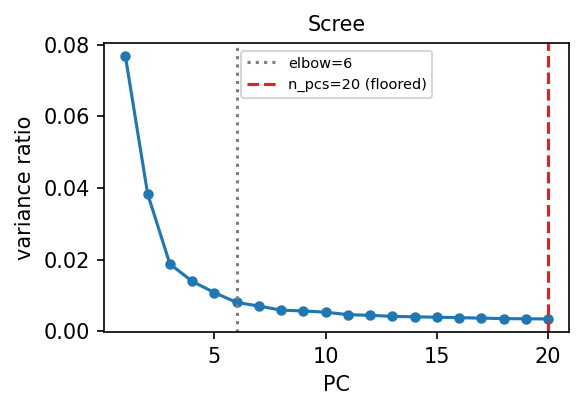

In [7]:
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
x = np.arange(len(vr)); p1 = np.array([x[0], vr[0]]); p2 = np.array([x[-1], vr[-1]])
d = np.abs(np.cross(p2 - p1, p1 - np.c_[x, vr])) / np.linalg.norm(p2 - p1)
elbow = int(np.argmax(d)) + 1
n_pcs = max(elbow, 20)
fig, ax = plt.subplots(figsize=(4, 2.5))
ax.plot(np.arange(1, 21), vr[:20], 'o-', ms=4)
ax.axvline(elbow, color='grey', ls=':', label=f'elbow={elbow}')
ax.axvline(n_pcs, color='tab:red', ls='--', label=f'n_pcs={n_pcs} (floored)')
ax.set_xlabel('PC'); ax.set_ylabel('variance ratio'); ax.legend(fontsize=7); ax.set_title('Scree', size=10)
plt.show()
print(f'elbow={elbow}; using n_pcs={n_pcs}')

### Gate 1 — mixing + continuity, judged on the embedding across a θ sweep
Malignant CLL cells are clonal B-cells: each patient's tumor is an independent expansion with private
IGH rearrangements/CNVs. We sweep Harmony strength θ ∈ {0,1,2,3,5} and read a **per-neighborhood**
metric (iLISI over the 7 samples; 1=segregated, 7=fully mixed) plus the regenerated UMAP — never a
single scalar.

In [8]:
def ilisi(rep, labels, k=90):
    lab = pd.Categorical(labels); codes = lab.codes; K = len(lab.categories)
    nn = NearestNeighbors(n_neighbors=k).fit(rep); _, idx = nn.kneighbors(rep)
    out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        p = np.bincount(codes[idx[i, 1:]], minlength=K) / (k - 1)
        out[i] = 1.0 / np.sum(p**2)
    return out

labels = adata.obs['sample'].values; Kn = adata.obs['sample'].nunique()
thetas = [0, 1, 2, 3, 5]; embeds = {}; il_summary = []
for th in thetas:
    ad = adata.copy()
    if th == 0:
        rep = ad.obsm['X_pca'][:, :n_pcs]
    else:
        sce.pp.harmony_integrate(ad, 'sample', theta=th, max_iter_harmony=20)
        rep = ad.obsm['X_pca_harmony'][:, :n_pcs]
    ad.obsm['X_use'] = rep
    il = ilisi(rep, labels)
    sc.pp.neighbors(ad, n_pcs=n_pcs, use_rep='X_use')
    sc.tl.umap(ad, spread=1.3, random_state=0)
    embeds[th] = ad
    il_summary.append((th, float(np.median(il)), float(il.mean())))
    print(f'theta={th}: iLISI median={np.median(il):.2f} mean={il.mean():.2f}  (max possible={Kn})')
il_df = pd.DataFrame(il_summary, columns=['theta', 'iLISI_median', 'iLISI_mean'])

theta=0: iLISI median=1.00 mean=1.09  (max possible=7)
theta=1: iLISI median=2.08 mean=2.52  (max possible=7)
theta=2: iLISI median=2.95 mean=3.09  (max possible=7)
theta=3: iLISI median=4.17 mean=4.12  (max possible=7)
theta=5: iLISI median=4.73 mean=4.65  (max possible=7)


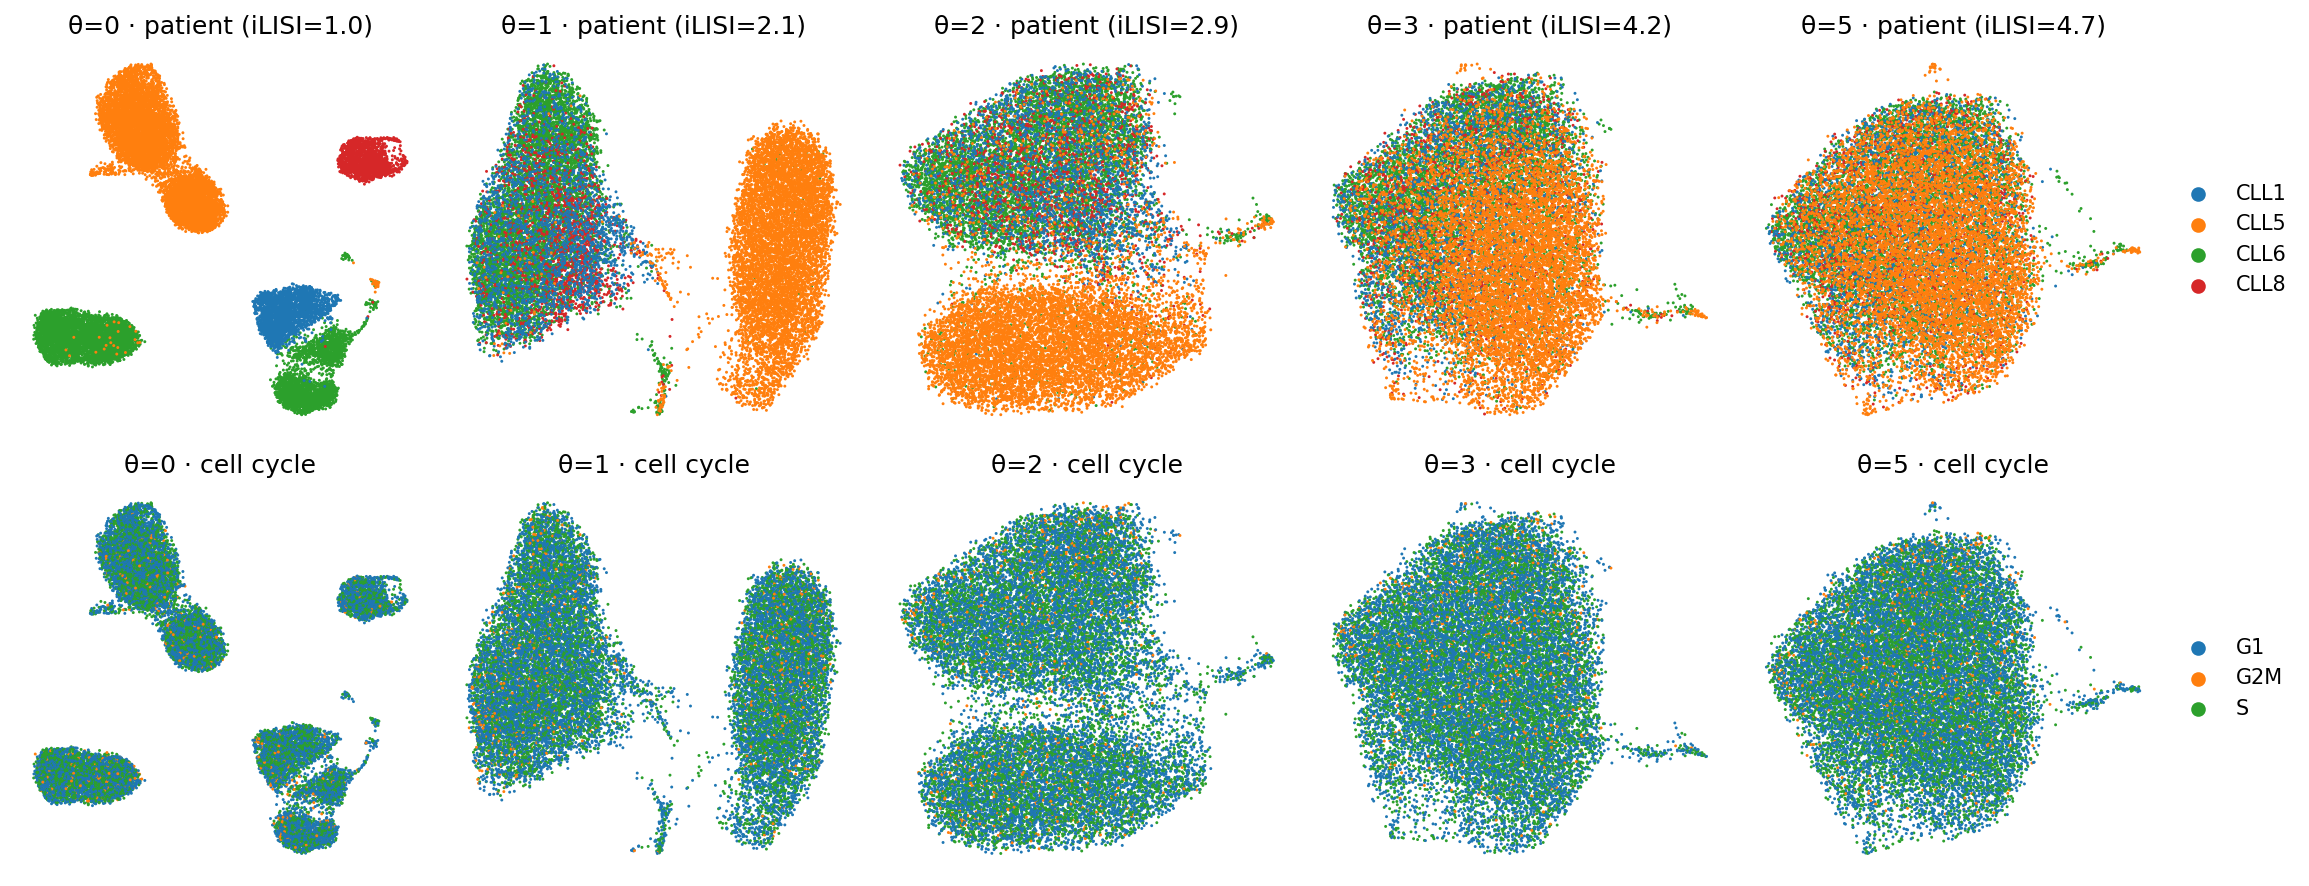

In [9]:
# regenerated embedding across the sweep — patient identity + cell cycle
fig, axes = plt.subplots(2, len(thetas), figsize=(3.1*len(thetas), 6.0))
for j, th in enumerate(thetas):
    ad = embeds[th]
    sc.pl.umap(ad, color='patient', size=8, ax=axes[0, j], show=False, frameon=False,
               legend_loc='right margin' if j == len(thetas)-1 else None,
               title=f'θ={th} · patient (iLISI={il_df.iloc[j].iLISI_median:.1f})')
    sc.pl.umap(ad, color='cell_cycle_phase', size=8, ax=axes[1, j], show=False, frameon=False,
               legend_loc='right margin' if j == len(thetas)-1 else None, title=f'θ={th} · cell cycle')
plt.tight_layout(); plt.show()

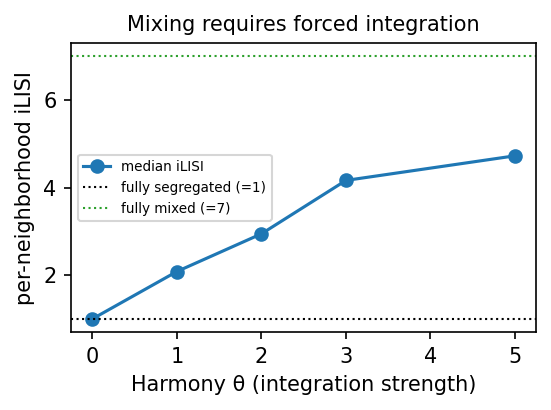

In [10]:
# iLISI vs theta — mixing only appears when integration is forced
fig, ax = plt.subplots(figsize=(4, 2.5))
ax.plot(il_df.theta, il_df.iLISI_median, 'o-', label='median iLISI')
ax.axhline(1, color='k', ls=':', lw=1, label='fully segregated (=1)')
ax.axhline(Kn, color='tab:green', ls=':', lw=1, label=f'fully mixed (={Kn})')
ax.set_xlabel('Harmony θ (integration strength)'); ax.set_ylabel('per-neighborhood iLISI')
ax.set_title('Mixing requires forced integration', size=10); ax.legend(fontsize=6.5)
plt.show()

**Is the structure biology or batch?** If cells segregate by *patient clone* (not a shared program),
the clusters are patient-pure and patient identity is kNN-predictable — the archipelago the spec forbids
forcing a trajectory through.

In [11]:
# patient-purity of clusters + kNN patient-identity predictability (unintegrated, θ=0)
ad0 = embeds[0]
sc.tl.leiden(ad0, resolution=0.5, flavor='igraph', n_iterations=2, directed=False)
ct = pd.crosstab(ad0.obs['leiden'], ad0.obs['patient'])
print('Leiden (θ=0) × patient crosstab:'); print(ct.to_string())
mean_purity = ct.max(axis=1).sum() / ct.values.sum()
print(f'\nmean cluster patient-purity: {mean_purity:.3f}')
lab = pd.Categorical(ad0.obs['patient']); codes = lab.codes
nn = NearestNeighbors(n_neighbors=31).fit(ad0.obsm['X_pca'][:, :n_pcs]); _, idx = nn.kneighbors(ad0.obsm['X_pca'][:, :n_pcs])
acc = np.mean([np.bincount(codes[idx[i, 1:]]).argmax() == codes[i] for i in range(len(codes))])
print(f'kNN (30-NN) patient-identity accuracy: {acc:.3f}  (chance = {1/len(lab.categories):.3f})')

Leiden (θ=0) × patient crosstab:
patient  CLL1  CLL5  CLL6  CLL8
leiden                         
0          16     0   917     2
1           0    36    78     1
2        2247     0    45     0
3           4     0  1602     0
4           0    22  4298     0
5           0     0     0  1555
6           0  4861     0     0
7           0  2890     0     0
8           0    83     0     0

mean cluster patient-purity: 0.993
kNN (30-NN) patient-identity accuracy: 0.995  (chance = 0.250)


In [12]:
# island structure: connected components on a UMAP radius graph across theta
def islands(ad, mult=3.0, min_frac=0.01):
    X = ad.obsm['X_umap']; nn = NearestNeighbors(n_neighbors=15).fit(X); d, _ = nn.kneighbors(X)
    r = mult * np.median(d[:, 1])
    A = nn.radius_neighbors_graph(X, radius=r, mode='connectivity')
    _, l = connected_components(A, directed=False); s = np.bincount(l)
    return int((s >= min_frac * X.shape[0]).sum()), sorted(s[s >= min_frac * X.shape[0]].tolist(), reverse=True)
for th in [0, 2, 3, 5]:
    big, sizes = islands(embeds[th])
    print(f'theta={th}: major islands (>=1% cells) = {big}  sizes={sizes}')

theta=0: major islands (>=1% cells) = 7  sizes=[4135, 4122, 2681, 1868, 1456, 1342, 697]
theta=2: major islands (>=1% cells) = 2  sizes=[9495, 6784]
theta=3: major islands (>=1% cells) = 1  sizes=[16450]
theta=5: major islands (>=1% cells) = 1  sizes=[16338]


### Annotation & island removal — assumptions checked (C3)
The manifold does **not** resolve into shared malignant subtypes; it fragments by **patient clone**
(purity ≈ 0.99, kNN patient-identity ≈ 0.99). The reference "keep the largest connected component"
island-removal rule assumes debris detaches cleanly — here the disconnected components *are* whole
patients, so removal would delete 3 of 4 patients (real biology, not noise). Island removal is therefore
**inapplicable**; all cells are retained. All cells carry the single malignant identity.

In [13]:
# canonical processed embedding = protocol-standard Harmony (harmonypy default theta=2)
adata = embeds[2].copy()
adata.obs['celltype'] = 'Malignant'
adata.obs['celltype'] = adata.obs['celltype'].astype('category')
# record derivation for provenance
adata.uns['gate1'] = dict(n_pcs=int(n_pcs), elbow=int(elbow),
                          ilisi_theta0=float(il_df.iloc[0].iLISI_median),
                          ilisi_theta2=float(il_df.iloc[2].iLISI_median),
                          ilisi_theta5=float(il_df.iloc[4].iLISI_median),
                          n_samples=int(Kn), patient_purity=float(mean_purity),
                          knn_patient_acc=float(acc), decision='NO-GO')
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad:', adata.shape)

saved processed.h5ad: (18657, 14889)


saved samples.pdf


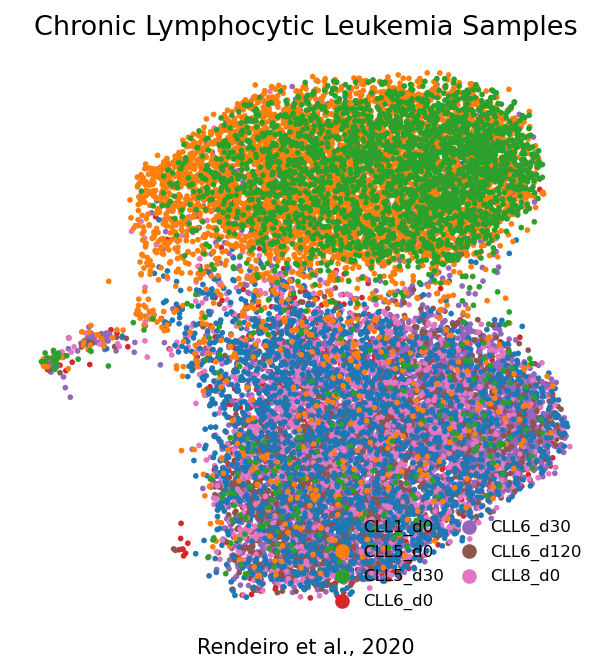

In [14]:
# --- samples.pdf : sample-colored manifold UMAP (reference layout) ---
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='sample', size=30, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=8)
ax.set_title('Chronic Lymphocytic Leukemia Samples', size=13)
ax.text(.5, -.05, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf')

## Gate 1 verdict — **NO-GO**
The malignant CLL manifold is **not sample-integrated**: unintegrated iLISI ≈ 1.0 of 7 (complete
per-patient segregation), Leiden clusters are 99.3% patient-pure, and patient identity is 99.5%
kNN-predictable. Mixing appears only when Harmony is forced (θ≥3), i.e. by collapsing patient centroids,
not by revealing a shared axis — and even the protocol-default θ=2 leaves two disconnected lobes. This is
a **per-patient archipelago**, the case the spec forbids forcing a trajectory through. No continuous,
sample-mixed manifold exists to fit.

**Consequence (§6):** stop at Gate 1. Deliverables = this notebook (01) + the unconditional EMT-TF
expression step, renumbered **02**. No manifold / signatures / correlation / modules notebooks are
produced. Geometry = NA; Gate 2 / Gate 3 = NA.